In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

from collections import defaultdict, deque

SEED = 42

np.random.seed(SEED)
random.seed(SEED)

plt.rcParams["figure.figsize"] = (9, 5)

print("Module IV initialized successfully.")

Module IV initialized successfully.


,State,Feature Vector,Estimated Value
0,S1,"[1.0, 0.0, 0.0, 0.0]",0.2
1,S2,"[1.0, 1.0, 0.0, 0.0]",0.7
2,S3,"[1.0, 0.0, 1.0, 0.0]",-0.1
3,S4,"[1.0, 1.0, 1.0, 0.0]",0.4
4,S5,"[1.0, 0.5, 0.5, 1.0]",0.4


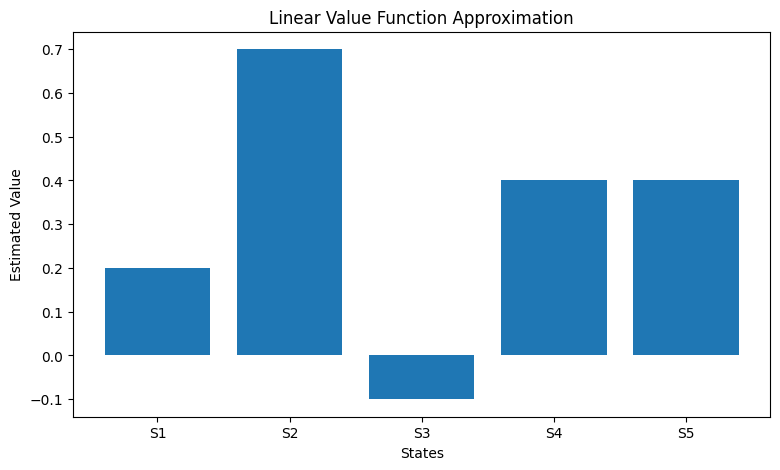

In [2]:
# Five states and four features

X = np.array([

    [1, 0, 0, 0],
    [1, 1, 0, 0],
    [1, 0, 1, 0],
    [1, 1, 1, 0],
    [1, 0.5, 0.5, 1]

], dtype=float)


# Initialize weights

weights = np.array([
    0.2,
    0.5,
    -0.3,
    0.1
])


# Linear approximation

values = X @ weights


df = pd.DataFrame({

    "State": ["S1", "S2", "S3", "S4", "S5"],

    "Feature Vector": [x.tolist() for x in X],

    "Estimated Value": values

})


display(df)


plt.bar(df["State"], df["Estimated Value"])

plt.title("Linear Value Function Approximation")

plt.xlabel("States")
plt.ylabel("Estimated Value")

plt.show()

In [3]:
states = ["S1", "S2", "S3"]

features = {

    "S1": np.array([1, 0, 0]),
    "S2": np.array([0, 1, 0]),
    "S3": np.array([0, 0, 1])

}

rewards = [2, 4, 8]

gamma = 0.9


def generate_episode():

    return [

        ("S1", 2, "S2"),
        ("S2", 4, "S3"),
        ("S3", 8, None)

    ]


def predict_value(weights, state):

    if state is None:
        return 0

    return np.dot(weights, features[state])

Gradient MC Final Values
S1 11.505565704261093
S2 10.667411911235451
S3 7.619579936596754


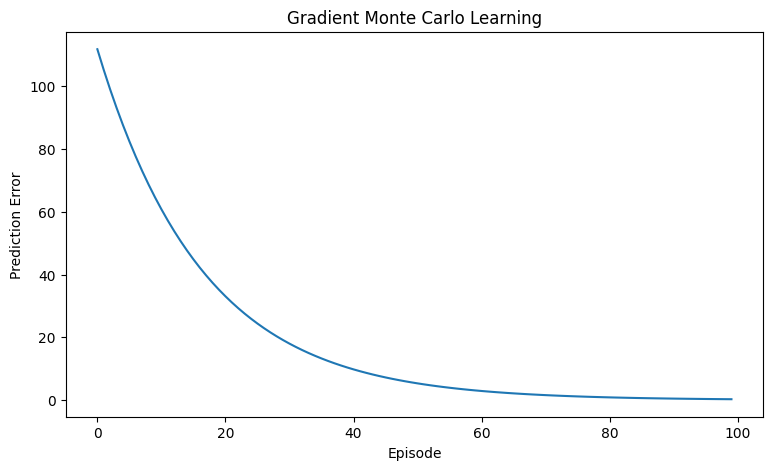

In [4]:
def gradient_mc(episodes=100, alpha=0.03):

    weights = np.zeros(3)

    errors = []

    for episode in range(episodes):

        data = generate_episode()

        G = 0
        returns = []

        for state, reward, next_state in reversed(data):

            G = reward + gamma * G

            returns.insert(0, G)

        episode_error = 0

        for (state, reward, next_state), G in zip(data, returns):

            prediction = predict_value(
                weights, state
            )

            error = G - prediction

            episode_error += error ** 2

            weights += (
                alpha * error * features[state]
            )

        errors.append(episode_error / len(data))

    return weights, errors


mc_weights, mc_errors = gradient_mc()


print("Gradient MC Final Values")

for state in states:

    print(
        state,
        predict_value(mc_weights, state)
    )


plt.plot(mc_errors)

plt.xlabel("Episode")
plt.ylabel("Prediction Error")

plt.title("Gradient Monte Carlo Learning")

plt.show()

In [5]:
def semi_gradient_td(episodes=100, alpha=0.05):

    weights = np.zeros(3)

    snapshots = {}

    for episode in range(1, episodes + 1):

        for state, reward, next_state in generate_episode():

            current_value = predict_value(
                weights, state
            )

            next_value = predict_value(
                weights, next_state
            )

            td_error = (
                reward +
                gamma * next_value -
                current_value
            )

            weights += (
                alpha *
                td_error *
                features[state]
            )

        if episode in [10, 50, 100]:

            snapshots[episode] = weights.copy()

    return weights, snapshots


td_weights, snapshots = semi_gradient_td()


for episode, weights in snapshots.items():

    print(f"\nAfter {episode} Episodes")

    for state in states:

        print(
            state,
            predict_value(weights, state)
        )


After 10 Episodes
S1 1.1871672545786252
S2 2.2252484055215627
S3 3.210104486092969

After 50 Episodes
S1 7.4175011058696105
S2 8.880311482184139
S3 7.384440197786295

After 100 Episodes
S1 11.16832246990127
S2 10.909333175961706
S3 7.952635766237329


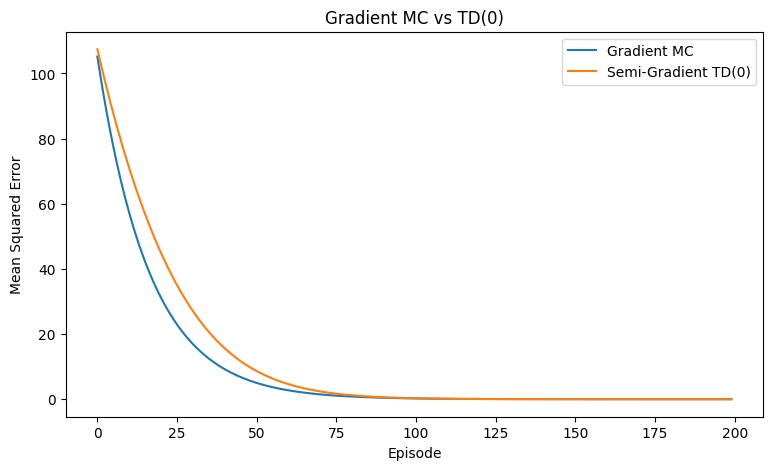

In [6]:
def compare_algorithms(episodes=200):

    w_mc = np.zeros(3)
    w_td = np.zeros(3)

    mc_errors = []
    td_errors = []

    true_values = np.array([
        2 + 0.9 * 4 + 0.9**2 * 8,
        4 + 0.9 * 8,
        8
    ])

    for episode in range(episodes):

        data = generate_episode()

        G = 0
        returns = []

        for state, reward, next_state in reversed(data):

            G = reward + gamma * G

            returns.insert(0, G)

        for (state, reward, next_state), G in zip(data, returns):

            prediction = predict_value(w_mc, state)

            error = G - prediction

            w_mc += 0.03 * error * features[state]

        for state, reward, next_state in data:

            prediction = predict_value(w_td, state)

            next_prediction = predict_value(
                w_td, next_state
            )

            error = (
                reward +
                gamma * next_prediction -
                prediction
            )

            w_td += 0.05 * error * features[state]

        mc_errors.append(
            np.mean((w_mc - true_values) ** 2)
        )

        td_errors.append(
            np.mean((w_td - true_values) ** 2)
        )

    return mc_errors, td_errors


mc_errors, td_errors = compare_algorithms()


plt.plot(mc_errors, label="Gradient MC")

plt.plot(td_errors, label="Semi-Gradient TD(0)")

plt.xlabel("Episode")
plt.ylabel("Mean Squared Error")

plt.title("Gradient MC vs TD(0)")

plt.legend()

plt.show()

,0.0,0.4,0.8,1.0
S1,8.564113,9.862129,10.998232,11.505566
S2,9.608511,10.032071,10.455632,10.667412
S3,7.619580,7.619580,7.619580,7.619580


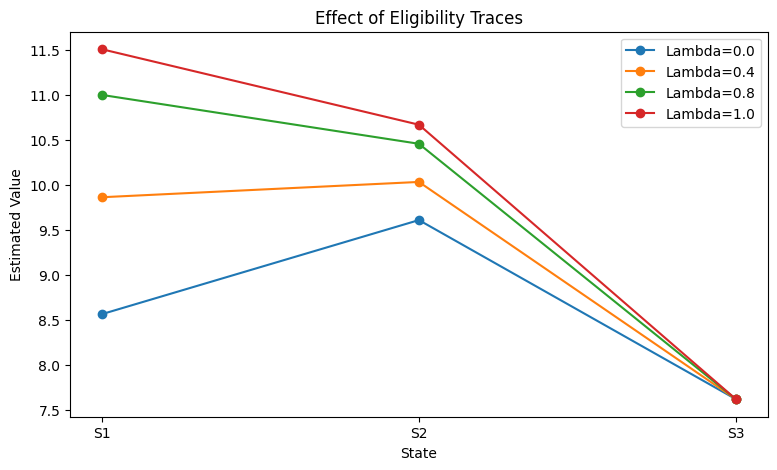

In [7]:
def td_lambda(episodes=100, alpha=0.03, lam=0.5):

    weights = np.zeros(3)

    for episode in range(episodes):

        eligibility = np.zeros(3)

        for state, reward, next_state in generate_episode():

            eligibility = (
                gamma * lam * eligibility +
                features[state]
            )

            prediction = predict_value(
                weights, state
            )

            next_prediction = predict_value(
                weights, next_state
            )

            td_error = (
                reward +
                gamma * next_prediction -
                prediction
            )

            weights += (
                alpha *
                td_error *
                eligibility
            )

    return weights


lambda_values = [0.0, 0.4, 0.8, 1.0]

results = {}

for lam in lambda_values:

    results[lam] = td_lambda(lam=lam)


lambda_df = pd.DataFrame(
    results,
    index=states
)

display(lambda_df)


for lam, weights in results.items():

    plt.plot(
        states,
        weights,
        marker="o",
        label=f"Lambda={lam}"
    )


plt.title("Effect of Eligibility Traces")

plt.xlabel("State")
plt.ylabel("Estimated Value")

plt.legend()

plt.show()

In [8]:
actions = ["A1", "A2"]

weights = np.array([
    0.2, -0.1, 0.4, 0.3, -0.2
])


def feature_vector(state, action):

    x = np.zeros(5)

    x[state] = 1

    x[3 + action] = 1

    return x


def q_value(state, action):

    return np.dot(
        weights,
        feature_vector(state, action)
    )


results = []

for state in range(3):

    q_values = []

    for action in range(2):

        q = q_value(state, action)

        q_values.append(q)

        results.append({

            "State": f"S{state+1}",

            "Action": actions[action],

            "Q-Value": q

        })

    selected_action = np.argmax(q_values)

    print(
        f"State S{state+1}: Selected Action = "
        f"{actions[selected_action]}"
    )


display(pd.DataFrame(results))

State S1: Selected Action = A1
State S2: Selected Action = A1
State S3: Selected Action = A1


,State,Action,Q-Value
0,S1,A1,0.5
1,S1,A2,0.0
2,S2,A1,0.2
3,S2,A2,-0.3
4,S3,A1,0.7
5,S3,A2,0.2


In [9]:
GRID_SIZE = 3

START = (0, 0)

GOAL = (2, 2)

ACTIONS = {
    0: (-1, 0),
    1: (1, 0),
    2: (0, -1),
    3: (0, 1)
}


def step(state, action):

    dr, dc = ACTIONS[action]

    next_state = (

        int(np.clip(state[0] + dr, 0, 2)),

        int(np.clip(state[1] + dc, 0, 2))

    )

    done = next_state == GOAL

    reward = 10 if done else -1

    return next_state, reward, done


def state_index(state):

    return state[0] * 3 + state[1]


def feature(state, action):

    x = np.zeros(36)

    x[state_index(state) * 4 + action] = 1

    return x

In [10]:
def train_approximate_q_learning(episodes=400):

    weights = np.zeros(36)

    alpha = 0.08
    gamma = 0.95

    epsilon = 1.0

    rewards_history = []
    td_errors = []
    epsilon_history = []

    for episode in range(episodes):

        state = START

        total_reward = 0

        episode_errors = []

        epsilon = max(
            0.05,
            1.0 * (0.99 ** episode)
        )

        done = False
        steps = 0

        while not done and steps < 100:

            q_values = [

                np.dot(weights, feature(state, a))

                for a in range(4)

            ]

            if random.random() < epsilon:

                action = random.randint(0, 3)

            else:

                action = int(np.argmax(q_values))

            next_state, reward, done = step(
                state, action
            )

            if done:

                target = reward

            else:

                next_q = max(

                    np.dot(
                        weights,
                        feature(next_state, a)
                    )

                    for a in range(4)

                )

                target = reward + gamma * next_q

            prediction = np.dot(
                weights,
                feature(state, action)
            )

            error = target - prediction

            weights += (
                alpha *
                error *
                feature(state, action)
            )

            episode_errors.append(abs(error))

            total_reward += reward

            state = next_state

            steps += 1

        rewards_history.append(total_reward)

        td_errors.append(np.mean(episode_errors))

        epsilon_history.append(epsilon)

    return weights, rewards_history, td_errors, epsilon_history


weights, rewards_history, td_errors, epsilon_history = (
    train_approximate_q_learning()
)

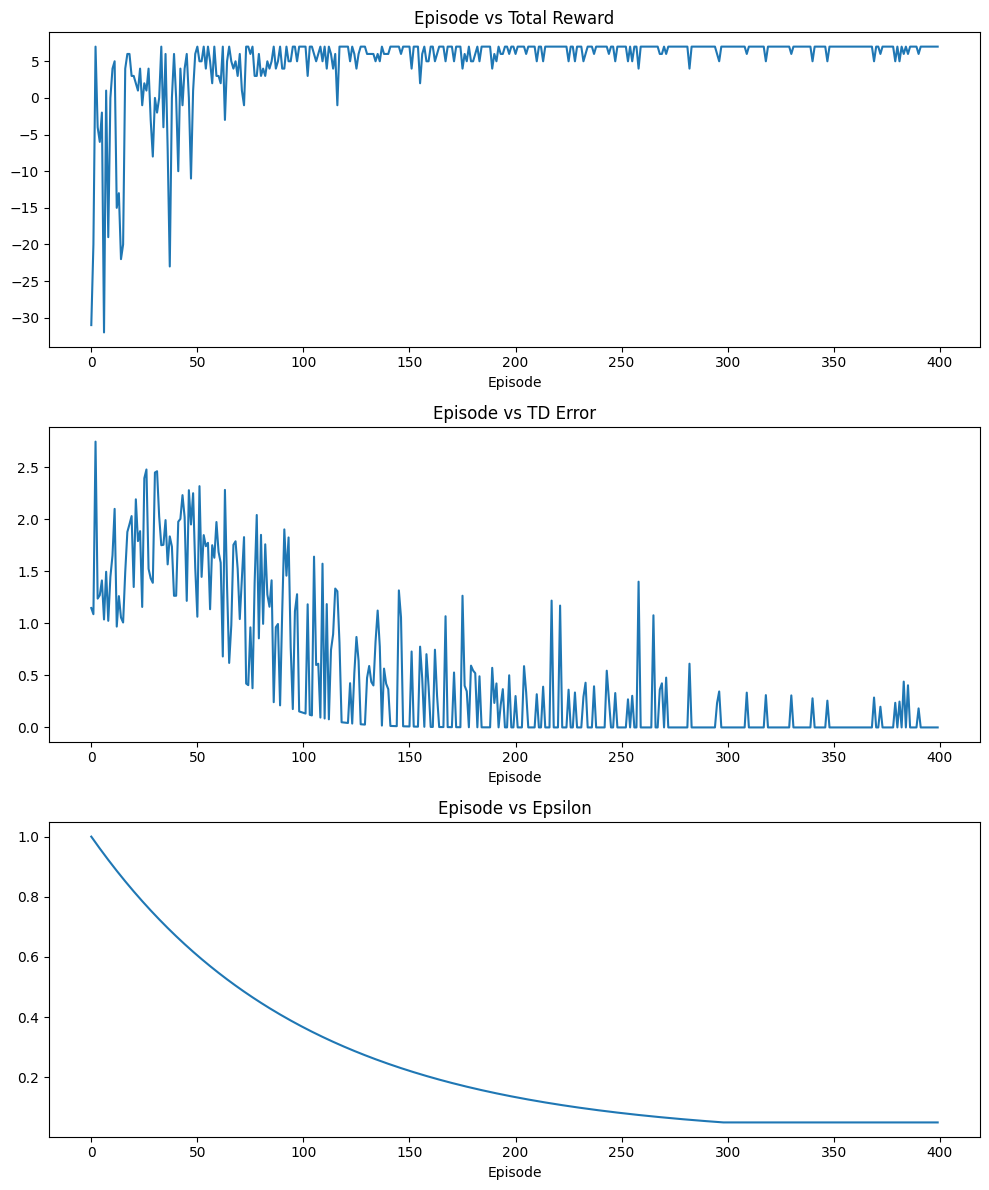

In [11]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))

axes[0].plot(rewards_history)

axes[0].set_title("Episode vs Total Reward")

axes[0].set_xlabel("Episode")

axes[1].plot(td_errors)

axes[1].set_title("Episode vs TD Error")

axes[1].set_xlabel("Episode")

axes[2].plot(epsilon_history)

axes[2].set_title("Episode vs Epsilon")

axes[2].set_xlabel("Episode")

plt.tight_layout()

plt.show()

In [12]:
class ReplayBuffer:

    def __init__(self, capacity=1000):

        self.memory = deque(maxlen=capacity)

    def store(self, transition):

        self.memory.append(transition)

    def sample(self, batch_size=32):

        return random.sample(
            self.memory,
            min(batch_size, len(self.memory))
        )

    def __len__(self):

        return len(self.memory)


memory = ReplayBuffer(capacity=1000)


# Example transitions

for i in range(100):

    transition = (

        (0, 0),

        random.randint(0, 3),

        random.randint(-1, 10),

        (1, 1),

        False

    )

    memory.store(transition)


batch = memory.sample(32)

print("Replay Memory Size:", len(memory))

print("Mini-Batch Size:", len(batch))

Replay Memory Size: 100
Mini-Batch Size: 32


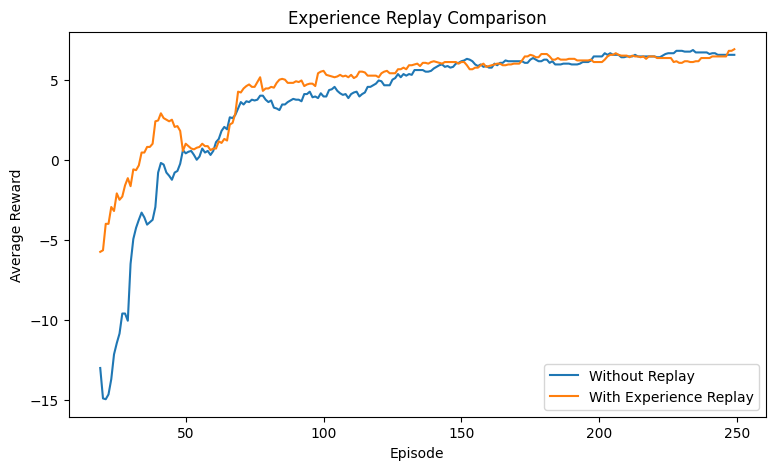

In [13]:
def train_with_replay(episodes=250, use_replay=True):

    weights = np.zeros(36)

    memory = ReplayBuffer(1000)

    alpha = 0.03
    gamma = 0.95

    rewards_history = []

    for episode in range(episodes):

        state = START

        total_reward = 0

        epsilon = max(0.05, 0.99 ** episode)

        done = False
        steps = 0

        while not done and steps < 100:

            q_values = [

                np.dot(weights, feature(state, a))

                for a in range(4)

            ]

            if random.random() < epsilon:

                action = random.randint(0, 3)

            else:

                action = int(np.argmax(q_values))

            next_state, reward, done = step(
                state, action
            )

            memory.store((
                state,
                action,
                reward,
                next_state,
                done
            ))

            if use_replay and len(memory) >= 32:

                batch = memory.sample(32)

            else:

                batch = [(
                    state,
                    action,
                    reward,
                    next_state,
                    done
                )]

            for s, a, r, ns, terminal in batch:

                if terminal:

                    target = r

                else:

                    target = r + gamma * max(

                        np.dot(
                            weights,
                            feature(ns, next_action)
                        )

                        for next_action in range(4)

                    )

                prediction = np.dot(
                    weights,
                    feature(s, a)
                )

                error = target - prediction

                weights += (
                    alpha *
                    error *
                    feature(s, a)
                )

            state = next_state

            total_reward += reward

            steps += 1

        rewards_history.append(total_reward)

    return weights, rewards_history


online_weights, online_rewards = train_with_replay(
    use_replay=False
)

replay_weights, replay_rewards = train_with_replay(
    use_replay=True
)


plt.plot(
    pd.Series(online_rewards).rolling(20).mean(),
    label="Without Replay"
)

plt.plot(
    pd.Series(replay_rewards).rolling(20).mean(),
    label="With Experience Replay"
)

plt.xlabel("Episode")

plt.ylabel("Average Reward")

plt.title("Experience Replay Comparison")

plt.legend()

plt.show()

In [14]:
!pip -q install "gymnasium[classic-control]" torch

In [15]:
import gymnasium as gym

import torch
import torch.nn as nn
import torch.optim as optim

from collections import deque, namedtuple

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", DEVICE)

Using device: cpu


In [16]:
class DQN(nn.Module):

    def __init__(self, input_dim, output_dim):

        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, 128),

            nn.ReLU(),

            nn.Linear(128, 128),

            nn.ReLU(),

            nn.Linear(128, output_dim)

        )

    def forward(self, x):

        return self.network(x)

In [17]:
Transition = namedtuple(

    "Transition",

    ["state", "action", "reward", "next_state", "done"]

)


class DQNReplayBuffer:

    def __init__(self, capacity=10000):

        self.memory = deque(maxlen=capacity)

    def push(self, *args):

        self.memory.append(
            Transition(*args)
        )

    def sample(self, batch_size):

        return random.sample(
            self.memory,
            batch_size
        )

    def __len__(self):

        return len(self.memory)

In [18]:
def train_dqn(episodes=300):

    env = gym.make("CartPole-v1")

    state_dim = env.observation_space.shape[0]

    action_dim = env.action_space.n

    policy_net = DQN(
        state_dim,
        action_dim
    ).to(DEVICE)

    target_net = DQN(
        state_dim,
        action_dim
    ).to(DEVICE)

    target_net.load_state_dict(
        policy_net.state_dict()
    )

    optimizer = optim.Adam(
        policy_net.parameters(),
        lr=0.001
    )

    replay = DQNReplayBuffer(10000)

    gamma = 0.99

    epsilon = 1.0

    epsilon_min = 0.05

    epsilon_decay = 0.992

    batch_size = 64

    rewards_history = []

    losses_history = []

    epsilon_history = []

    for episode in range(episodes):

        state, info = env.reset(seed=SEED + episode)

        total_reward = 0

        episode_losses = []

        done = False

        while not done:

            if random.random() < epsilon:

                action = env.action_space.sample()

            else:

                with torch.no_grad():

                    state_tensor = torch.tensor(
                        state,
                        dtype=torch.float32,
                        device=DEVICE
                    ).unsqueeze(0)

                    action = policy_net(
                        state_tensor
                    ).argmax(1).item()

            next_state, reward, terminated, truncated, info = env.step(action)

            done = terminated or truncated

            replay.push(
                state,
                action,
                reward,
                next_state,
                done
            )

            state = next_state

            total_reward += reward

            if len(replay) >= batch_size:

                batch = replay.sample(batch_size)

                states = torch.tensor(
                    np.array([t.state for t in batch]),
                    dtype=torch.float32,
                    device=DEVICE
                )

                actions = torch.tensor(
                    [t.action for t in batch],
                    dtype=torch.long,
                    device=DEVICE
                ).unsqueeze(1)

                rewards_batch = torch.tensor(
                    [t.reward for t in batch],
                    dtype=torch.float32,
                    device=DEVICE
                )

                next_states = torch.tensor(
                    np.array([t.next_state for t in batch]),
                    dtype=torch.float32,
                    device=DEVICE
                )

                dones = torch.tensor(
                    [t.done for t in batch],
                    dtype=torch.float32,
                    device=DEVICE
                )

                current_q = policy_net(
                    states
                ).gather(1, actions).squeeze(1)

                with torch.no_grad():

                    next_q = target_net(
                        next_states
                    ).max(1)[0]

                    target_q = (
                        rewards_batch +
                        gamma * next_q * (1 - dones)
                    )

                loss = nn.functional.smooth_l1_loss(
                    current_q,
                    target_q
                )

                optimizer.zero_grad()

                loss.backward()

                nn.utils.clip_grad_norm_(
                    policy_net.parameters(),
                    10
                )

                optimizer.step()

                episode_losses.append(loss.item())

            # Update target network periodically

            if total_reward > 0 and int(total_reward) % 20 == 0:

                pass

        epsilon = max(
            epsilon_min,
            epsilon * epsilon_decay
        )

        rewards_history.append(total_reward)

        losses_history.append(
            np.mean(episode_losses)
            if episode_losses else 0
        )

        epsilon_history.append(epsilon)

        if (episode + 1) % 25 == 0:

            print(
                f"Episode: {episode+1} | "
                f"Reward: {total_reward} | "
                f"Epsilon: {epsilon:.3f}"
            )

        if (episode + 1) % 10 == 0:

            target_net.load_state_dict(
                policy_net.state_dict()
            )

    env.close()

    return (
        policy_net,
        rewards_history,
        losses_history,
        epsilon_history
    )


model, dqn_rewards, dqn_losses, dqn_epsilon = train_dqn()

Episode: 25 | Reward: 43.0 | Epsilon: 0.818
Episode: 50 | Reward: 20.0 | Epsilon: 0.669
Episode: 75 | Reward: 59.0 | Epsilon: 0.547
Episode: 100 | Reward: 19.0 | Epsilon: 0.448
Episode: 125 | Reward: 106.0 | Epsilon: 0.366
Episode: 150 | Reward: 18.0 | Epsilon: 0.300
Episode: 175 | Reward: 22.0 | Epsilon: 0.245
Episode: 200 | Reward: 104.0 | Epsilon: 0.201
Episode: 225 | Reward: 113.0 | Epsilon: 0.164
Episode: 250 | Reward: 124.0 | Epsilon: 0.134
Episode: 275 | Reward: 133.0 | Epsilon: 0.110
Episode: 300 | Reward: 139.0 | Epsilon: 0.090


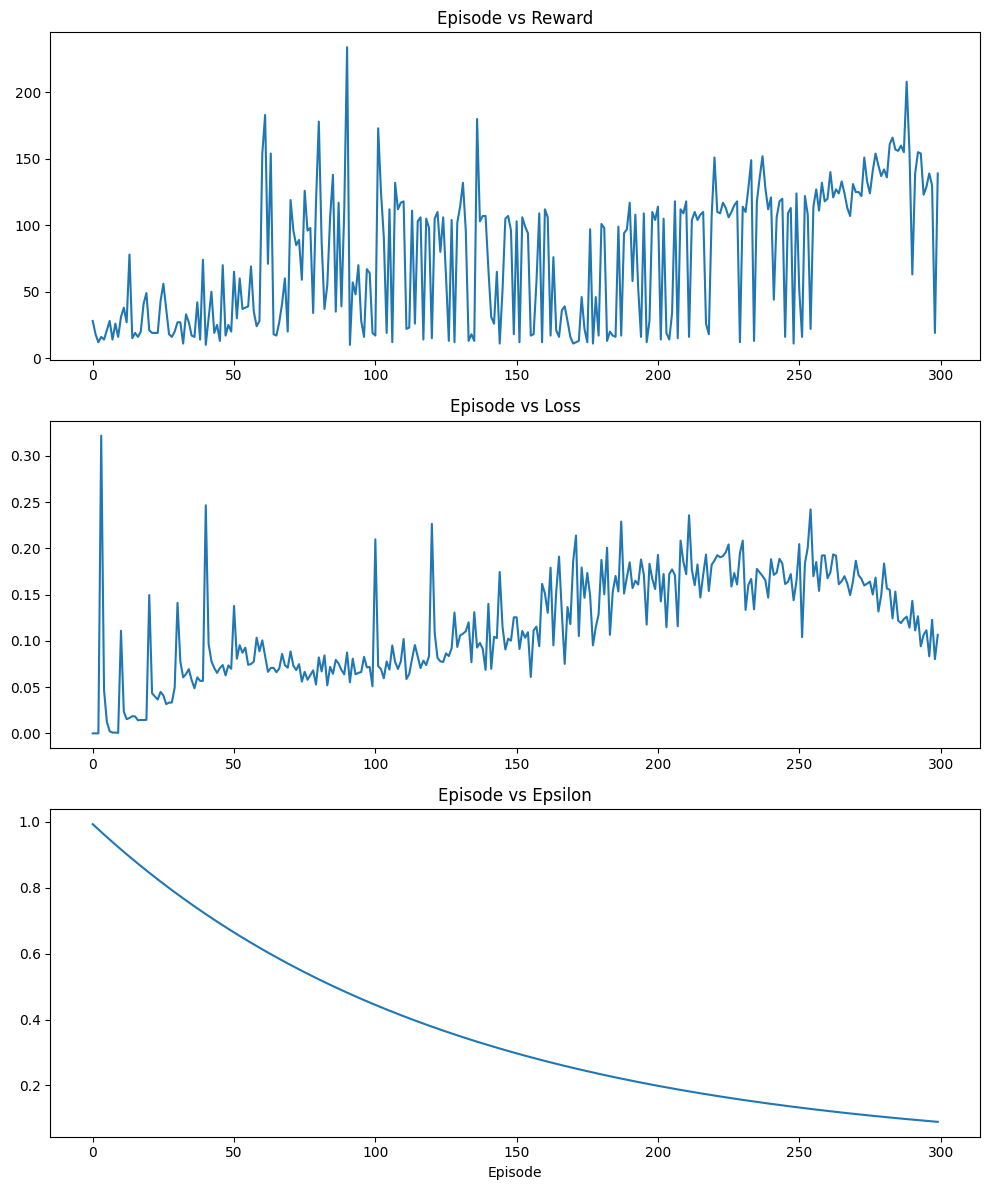

Average Reward (Last 20 Episodes): 139.3


In [19]:
fig, axes = plt.subplots(3, 1, figsize=(10, 12))

axes[0].plot(dqn_rewards)

axes[0].set_title("Episode vs Reward")

axes[1].plot(dqn_losses)

axes[1].set_title("Episode vs Loss")

axes[2].plot(dqn_epsilon)

axes[2].set_title("Episode vs Epsilon")

axes[2].set_xlabel("Episode")

plt.tight_layout()

plt.show()


print(
    "Average Reward (Last 20 Episodes):",
    np.mean(dqn_rewards[-20:])
)